In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr
import seaborn as sns

In [2]:
import data                       

In [3]:
plt.style.use("../../nice.mplstyle")

In [4]:
fig_dir = "figures"
if not os.path.isdir(fig_dir):
    os.makedirs(fig_dir)

In [6]:
ads = xr.open_dataset("runs/v0.10k/inference-validation/metrics/sla.all_groups.nc", chunks="auto")
ads = ads.squeeze()
ads.load();

In [7]:
sds = data.open_anemoi_statistics()
sds

<xarray.Dataset> Size: 4kB
Dimensions:   (variable: 50)
Coordinates:
  * variable  (variable) object 400B 'cos_julian_day' ... 'pooled'
Data variables:
    mean      (variable) float64 400B 0.005335 0.8092 -0.101 ... 0.03197 0.04331
    stdev     (variable) float64 400B 0.708 0.202 0.7257 ... 0.08487 0.09025
    minimum   (variable) float64 400B -1.0 0.01276 -1.0 ... -1.293 -1.169 -1.336
    maximum   (variable) float64 400B 1.0 1.0 1.0 -5.331 ... 1.295 1.015 1.342
    sums      (variable) float64 400B 1.641e+06 2.489e+08 ... 1.123e+05 nan
    squares   (variable) float64 400B 1.542e+08 2.14e+08 ... 2.889e+04 nan
    count     (variable) float64 400B 3.076e+08 3.076e+08 ... 3.512e+06 nan
    has_nans  (variable) float64 400B 0.0 0.0 0.0 0.0 0.0 ... 1.0 1.0 1.0 nan
Attributes: (12/33)
    allow_nans:                    True
    area_check_max:                1.0011764197238402
    area_check_min:                0.9992095208373891
    binned:                        True
    cell_selection:                gebco.land_fraction < 0.1
    constant_fields:               ['cos_latitude', 'cos_longitude', 'elevati...
    ...                            ...
    statistics_end_date:           2018-12-30T12:00:00
    statistics_start_date:         1993-11-01T12:00:00
    time_bin_closed:               left
    time_bin_label:                middle
    variables:                     ['cos_julian_day', 'cos_latitude', 'cos_lo...
    variables_metadata:            {'cos_julian_day': {'computed_forcing': Tr...

In [8]:
def histplot(metric, show_stdev=False):
    
    fig, axs = plt.subplots(1, 2, figsize=(12,5))
    
    ax = axs[0]
    for varname, label in zip(
        [metric, f"{metric}_pooled"],
        ["Raw Mean", "$N_{obs}$ Weighted"],
    ):
        sns.histplot(
            ads[varname],
            ax=ax,
            label=label,
        )

    if show_stdev:
        ax.axvline(x=sds["stdev"].sel(variable="pooled"), color="gray", label="Pooled Training Std. Dev.")
    ax.legend()
    
    ax = axs[1]
    for varname in [
        "n_obs",
    ]:
        ads[varname].plot(ax=ax, label=varname, color="C3")
        ax.set(title="")
        ax.legend()
        

    return fig, axs

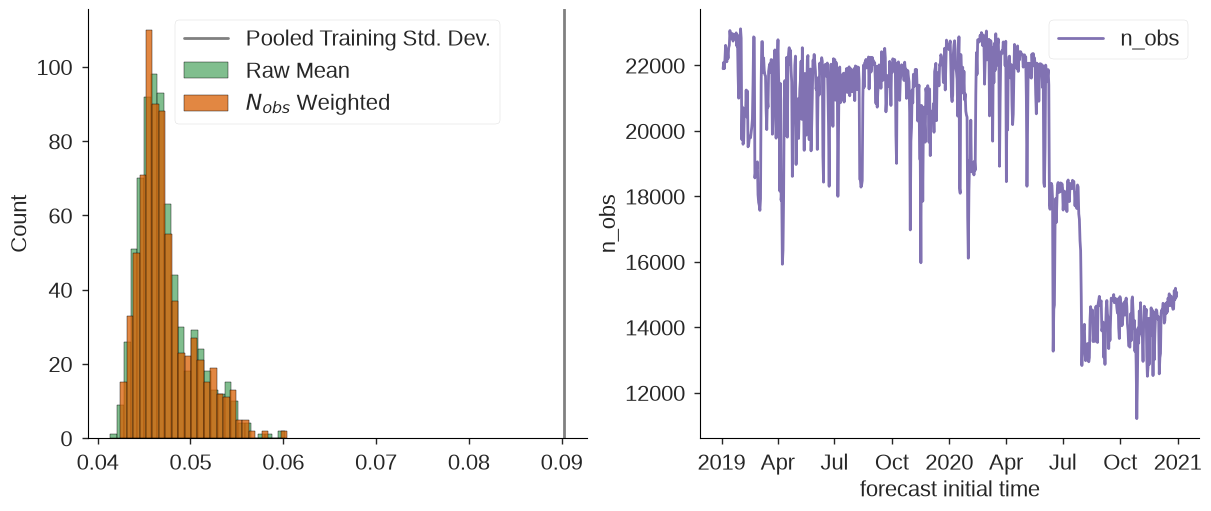

In [9]:
histplot("rmse", show_stdev=True);

(<Figure size 1200x500 with 2 Axes>,
 array([<Axes: ylabel='Count'>,
        <Axes: xlabel='forecast initial time', ylabel='n_obs'>],
       dtype=object))

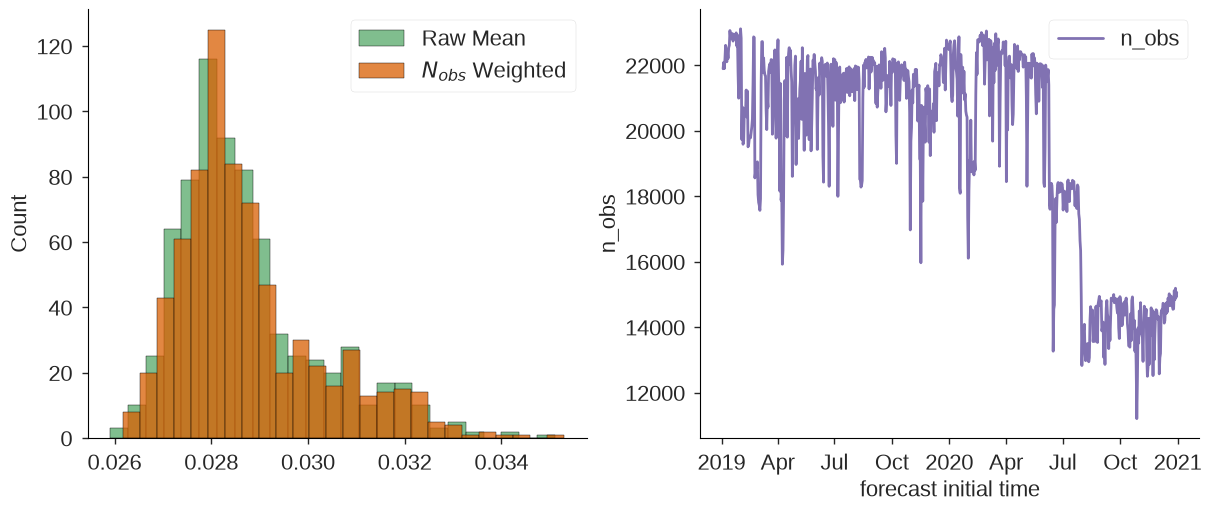

In [10]:
histplot("mae")

In [11]:
gds = xr.open_dataset("runs/v0.10k/inference-validation/metrics/sla.per_group.nc")
gds = gds.squeeze()
gds.load()

<xarray.Dataset> Size: 152kB
Dimensions:     (t0: 728, group: 6)
Coordinates:
  * t0          (t0) datetime64[ns] 6kB 2019-01-03T12:00:00 ... 2020-12-30T12...
    valid_time  (t0) datetime64[ns] 6kB 2019-01-04T12:00:00 ... 2020-12-31T12...
  * group       (group) <U19 456B 'cryosat_2' ... 'sentinel_3b'
    lead_time   timedelta64[ns] 8B 1 days
    fhr         int64 8B 24
Data variables:
    rmse        (t0, group) float64 35kB 0.04127 0.04599 ... 0.0561 0.05502
    mae         (t0, group) float64 35kB 0.02606 0.0287 ... 0.03241 0.0319
    bias        (t0, group) float64 35kB 0.001715 0.001465 ... -0.001566
    n_obs       (group, t0) int64 35kB 3760 3787 3745 3732 ... 3870 3689 3741

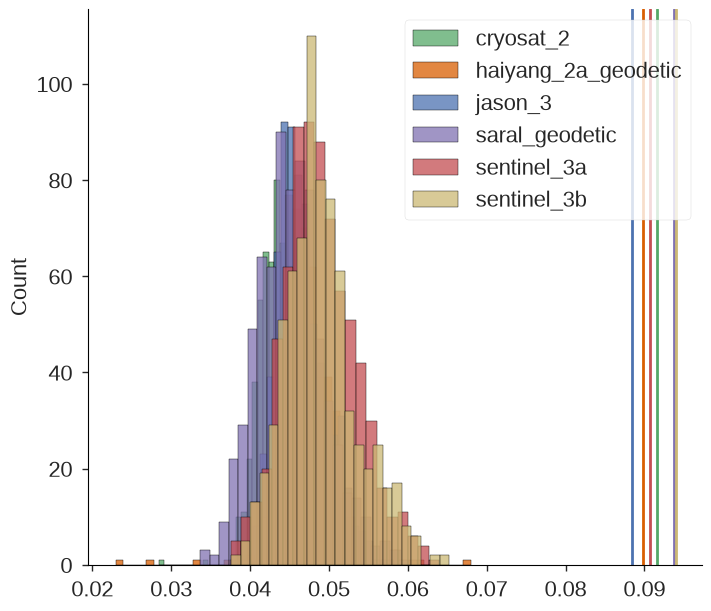

In [12]:
metric = "rmse"

fig, ax = plt.subplots()
for i, group in enumerate(gds.group.values):
    sns.histplot(
        gds[metric].sel(group=group),
        label=group,
        #alpha=.5
        color=f"C{i}",
    )
    ax.axvline(sds["stdev"].sel(variable=f"sla_filtered_{group}"), color=f"C{i}")
ax.legend();

## Observed at input

In [13]:
ods = xr.open_dataset("runs/v0.10k/inference-validation/metrics/sla.by_region.all_groups.nc")
ods = ods.squeeze()
ods.load()

<xarray.Dataset> Size: 152kB
Dimensions:        (t0: 728, region: 3)
Coordinates:
  * t0             (t0) datetime64[ns] 6kB 2019-01-03T12:00:00 ... 2020-12-30...
    valid_time     (t0) datetime64[ns] 6kB 2019-01-04T12:00:00 ... 2020-12-31...
  * region         (region) <U12 144B 'seen_at_t0' 'seen_earlier' 'unseen'
    lead_time      timedelta64[ns] 8B 1 days
    fhr            int64 8B 24
Data variables:
    rmse           (t0, region) float64 17kB 0.0379 0.04397 ... 0.04677 0.0608
    mae            (t0, region) float64 17kB 0.02405 0.02783 ... 0.02821 0.03686
    bias           (t0, region) float64 17kB 0.0001648 8.356e-05 ... -0.00403
    n_live_groups  (t0, region) int64 17kB 6 6 6 6 6 6 6 6 6 ... 4 4 4 4 4 4 4 4
    rmse_pooled    (t0, region) float64 17kB 0.03799 0.04406 ... 0.04754 0.06434
    mae_pooled     (t0, region) float64 17kB 0.02403 0.02789 ... 0.02843 0.03867
    bias_pooled    (t0, region) float64 17kB 0.0001824 0.0001777 ... -0.004171
    n_obs          (t0, region) int64 17kB 10705 8286 2905 ... 6634 4955 3473

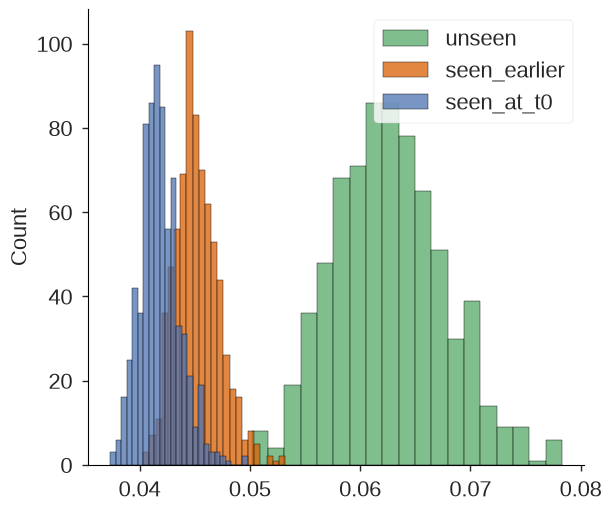

In [14]:
metric = "rmse"

fig, ax = plt.subplots(figsize=(6,5))
for region in ["unseen", "seen_earlier", "seen_at_t0"]:
    sns.histplot(
        ods[metric].sel(region=region),
        label=region,
        #alpha=.5
    )
ax.legend();

In [42]:
ogds = [
    xr.open_dataset(f"runs/v0.10k/inference-{period}/metrics/sla.by_region.per_group.nc").squeeze().load().expand_dims({"period": [period]})
    for period in ["2015", "validation"]
]
ogds = xr.concat(ogds, dim="period")


/tmp/ipykernel_704439/706638672.py:5: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'group' ('group',) The recommendation is to set join explicitly for this case.
  ogds = xr.concat(ogds, dim="period")
/tmp/ipykernel_704439/706638672.py:5: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 't0' ('t0',) The recommendation is to set join explicitly for this case.
  ogds = xr.concat(ogds, dim="period")
/tmp/ipykernel_704439/706638672.py:5: FutureWarning: In a future version of xarray the default value for coords will cha

In [43]:
pgds = [
    xr.open_dataset(f"runs/v0.10k/inference-{period}/persistence-metrics/sla.cryosat_2.per_group.nc").squeeze().load().expand_dims({"period": [period]})
    for period in ["2015", "validation"]
]
pgds = xr.concat(pgds, dim="period")

/tmp/ipykernel_704439/3567927776.py:5: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'group' ('group',) The recommendation is to set join explicitly for this case.
  pgds = xr.concat(pgds, dim="period")
/tmp/ipykernel_704439/3567927776.py:5: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 't0' ('t0',) The recommendation is to set join explicitly for this case.
  pgds = xr.concat(pgds, dim="period")


In [44]:
ogds = xr.concat([ogds.expand_dims({"myname": ["v0.10k"]}), pgds.expand_dims({"myname": ["cryosat2 persistence"]})], dim="myname")

In [45]:
def make_it_nice(ax):
    ax.set(
        xlabel="",
        ylabel=ax.get_ylabel().upper(),
        xticklabels=[x.get_text().replace("_"," ").capitalize() for x in ax.get_xticklabels()],
    )

In [55]:
def plot_observed_region(xds, metric, x="group", hue="region"):
    
    fig, ax = plt.subplots(figsize=(9,5))
    df = xds[metric].to_dataset().to_dataframe().reset_index()
    sns.violinplot(
        df,
        y=metric,
        x=x,
        #alpha=.5
        hue=hue,
    )

    groups = xds["group"].values
    if x == "group":
        stdev = sds["stdev"].sel(variable=[f"sla_filtered_{g}" for g in groups]).values
        x = np.arange(len(groups))

        if metric == "rmse":
            ax.hlines(stdev, x - 0.4, x + 0.4, color="gray", lw=1.5, zorder=3,
                      label="Training Std. Dev.")
    else:
        stdev = sds["stdev"].sel(variable="pooled").values
        if metric == "rmse":
            ax.axhline(stdev, color="gray", lw=1.5, zorder=3, label="Training Std. Dev.")
    if metric == "bias":
        ax.axhline(0, color="gray", lw=1.5, zorder=3)
        
        
    l = ax.legend(bbox_to_anchor=(1., .5), loc="center left");
    
    make_it_nice(ax)
    return fig, ax

/tmp/ipykernel_704439/1547974153.py:2: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set(


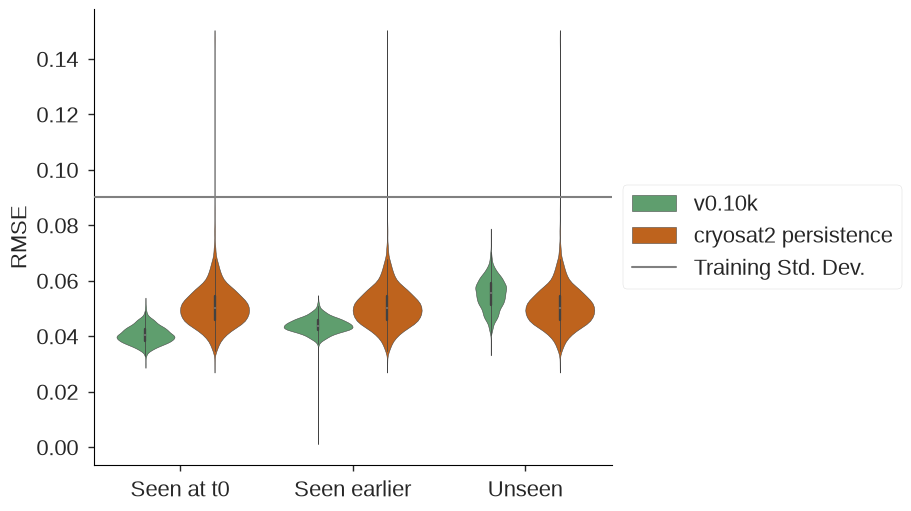

In [56]:
fig, ax = plot_observed_region(ogds.sel(period="2015"), "rmse", x="region", hue="myname");
#fig.savefig("runs/v3/figures/rmse_by_region_by_group.jpeg", bbox_inches="tight")

/tmp/ipykernel_704439/1547974153.py:2: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set(


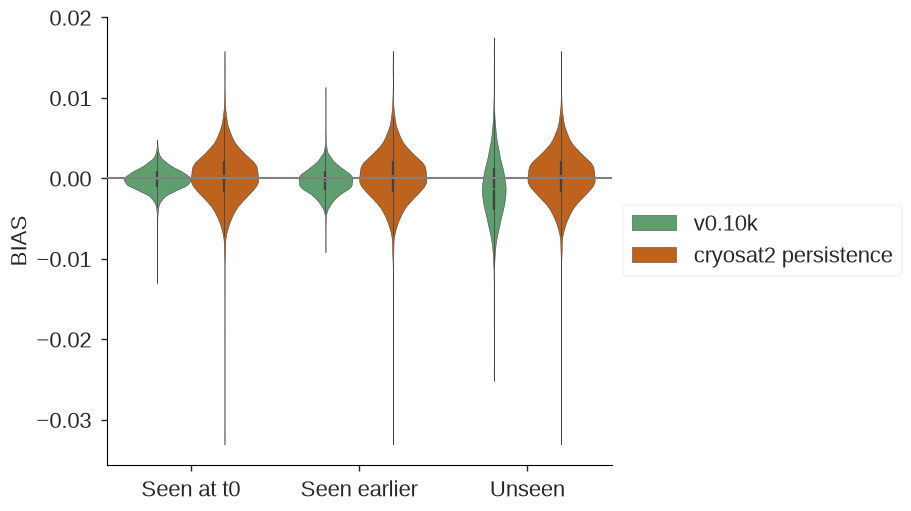

In [64]:
metric = "bias"
period = "validation"
fig, ax = plot_observed_region(ogds.sel(period=period), metric, x="region", hue="myname");
fig.savefig(f"{fig_dir}/{metric}.{period}.by_region.jpeg", bbox_inches="tight", dpi=300)

## Look at overlap degree

In [51]:
lgds = [
    xr.open_dataset(f"runs/v0.10k/inference-{period}/metrics/sla.by_overlap.per_group.nc").squeeze().load().expand_dims({"period": [period]})
    for period in ["2015", "validation"]
]
lgds = xr.concat(lgds, dim="period")

/tmp/ipykernel_704439/2147503208.py:5: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'group' ('group',) The recommendation is to set join explicitly for this case.
  lgds = xr.concat(lgds, dim="period")
/tmp/ipykernel_704439/2147503208.py:5: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 't0' ('t0',) The recommendation is to set join explicitly for this case.
  lgds = xr.concat(lgds, dim="period")
/tmp/ipykernel_704439/2147503208.py:5: FutureWarning: In a future version of xarray the default value for join will ch

/tmp/ipykernel_704439/1547974153.py:2: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set(


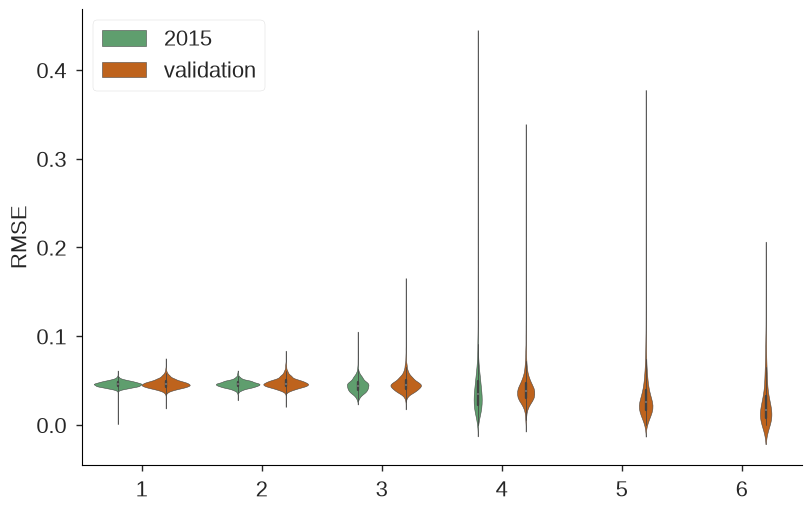

In [52]:
metric = "rmse"

fig, ax = plt.subplots(figsize=(8,5))
df = lgds[metric].to_dataset().to_dataframe().reset_index()
sns.violinplot(
    df,
    x="n_overlap",
    y="rmse",
    hue="period",
)
ax.legend();
make_it_nice(ax)
#fig.savefig(f"runs/v3/figures/rmse_by_overlap.jpeg", bbox_inches="tight")